In [1]:
# ============================================================
# 1. Imports
# ============================================================

import os

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

import glob
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

# ============================================================
# 2. Dataset path
# ============================================================

DATA_PATH = "./GEFCom2014-L_V2/Load"


tasks = sorted(
    glob.glob(DATA_PATH + "/Task */L*-train.csv")
)

print("Number of tasks:", len(tasks))

Number of tasks: 15


In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

DATA_PATH = Path("./GEFCom2014-L_V2/Load")
weather_cols = [f"w{i}" for i in range(1, 26)]


def task_number(path):
    match = re.fullmatch(r"L(\d+)-train", path.stem)
    if match is None:
        raise ValueError(f"Unexpected filename: {path.name}")
    return int(match.group(1))


def parse_task_timestamps(raw, number):
    """
    For the supplied GEFCom2014 archive.

    Raw dates have no separators or zero padding, so individual
    strings can be ambiguous. Reconstruct each task's hourly
    sequence and validate EVERY timestamp against the raw string.
    """
    if number == 1:
        start = pd.Timestamp("2001-01-01 01:00:00")
    else:
        start = (
            pd.Timestamp("2010-10-01 01:00:00")
            + pd.DateOffset(months=number - 2)
        )

    timestamps = pd.date_range(
        start=start,
        periods=len(raw),
        freq="h",
    )

    expected = [
        f"{t.month}{t.day}{t.year} {t.hour}:00"
        for t in timestamps
    ]
    actual = raw.astype(str).str.strip().tolist()

    for row, (observed, required) in enumerate(zip(actual, expected)):
        if observed != required:
            raise ValueError(
                f"Task {number}, row {row}: "
                f"raw timestamp {observed!r} does not match "
                f"expected {required!r}. Check the source file."
            )

    return timestamps


tasks = sorted(
    DATA_PATH.glob("Task */L*-train.csv"),
    key=task_number,
)

if [task_number(p) for p in tasks] != list(range(1, 16)):
    raise ValueError(
        "Expected training files for Tasks 1–15. Check DATA_PATH."
    )

all_data = []

for file in tasks:
    temp = pd.read_csv(file)
    temp["TIMESTAMP"] = parse_task_timestamps(
        temp["TIMESTAMP"],
        task_number(file),
    )
    all_data.append(temp)

df = (
    pd.concat(all_data, ignore_index=True)
    .sort_values(["ZONEID", "TIMESTAMP"])
    .reset_index(drop=True)
)

if df.duplicated(["ZONEID", "TIMESTAMP"]).any():
    raise ValueError("Unexpected duplicate zone/timestamp pairs.")

if df["ZONEID"].nunique() != 1:
    raise ValueError("This pipeline expects one zone.")

# The supplied archive has an initial weather-only period.
# Remove it; no resampling or interpolation is needed.
df_hourly = (
    df.loc[
        df["LOAD"].notna(),
        ["TIMESTAMP", "LOAD"] + weather_cols,
    ]
    .reset_index(drop=True)
)

assert len(df_hourly) == 60600
assert df_hourly[["LOAD"] + weather_cols].notna().all().all()

hourly_steps = df_hourly["TIMESTAMP"].diff().iloc[1:]
assert hourly_steps.eq(pd.Timedelta(hours=1)).all()

print("Raw rows:", len(df))
print("Labelled rows:", len(df_hourly))
print("Start:", df_hourly["TIMESTAMP"].iloc[0])
print("End:", df_hourly["TIMESTAMP"].iloc[-1])
print("Non-hourly gaps:", (~hourly_steps.eq(pd.Timedelta(hours=1))).sum())

Raw rows: 95664
Labelled rows: 60600
Start: 2005-01-01 01:00:00
End: 2011-12-01 00:00:00
Non-hourly gaps: 0


In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

HISTORY = 168
HORIZON = 24

df_hourly = (
    df_hourly
    .sort_values("TIMESTAMP")
    .reset_index(drop=True)
    .copy()
)

df_hourly["TIMESTAMP"] = pd.to_datetime(df_hourly["TIMESTAMP"])

# --------------------------------------------------
# 1. Calendar features — create BEFORE splitting
# --------------------------------------------------

hour = df_hourly["TIMESTAMP"].dt.hour
dow = df_hourly["TIMESTAMP"].dt.dayofweek
month = df_hourly["TIMESTAMP"].dt.month

df_hourly["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df_hourly["hour_cos"] = np.cos(2 * np.pi * hour / 24)

df_hourly["dow_sin"] = np.sin(2 * np.pi * dow / 7)
df_hourly["dow_cos"] = np.cos(2 * np.pi * dow / 7)

df_hourly["month_sin"] = np.sin(2 * np.pi * month / 12)
df_hourly["month_cos"] = np.cos(2 * np.pi * month / 12)

calendar_cols = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

weather_cols = [f"w{i}" for i in range(1, 26)]

# --------------------------------------------------
# 2. Chronological splits
# Validation/test include past context only.
# Their targets start at the intended boundaries.
# --------------------------------------------------

n = len(df_hourly)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = df_hourly.iloc[:train_end].copy()
val_df = df_hourly.iloc[train_end - HISTORY:val_end].copy()
test_df = df_hourly.iloc[val_end - HISTORY:].copy()

# --------------------------------------------------
# 3. Fit scalers ONLY on training data
# --------------------------------------------------

load_scaler = StandardScaler()
weather_scaler = StandardScaler()

load_scaler.fit(train_df[["LOAD"]])
weather_scaler.fit(train_df[weather_cols])

scaled_weather_cols = [f"{c}_scaled" for c in weather_cols]

for split in (train_df, val_df, test_df):
    split["LOAD_scaled"] = load_scaler.transform(
        split[["LOAD"]]
    ).ravel()

    split[scaled_weather_cols] = weather_scaler.transform(
        split[weather_cols]
    )

# --------------------------------------------------
# 4. Validate all required dataset inputs
# --------------------------------------------------

required_cols = (
    ["LOAD_scaled"]
    + scaled_weather_cols
    + calendar_cols
)

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    missing = [c for c in required_cols if c not in split.columns]
    assert not missing, f"{name}: missing columns {missing}"

    assert np.isfinite(
        split[required_cols].to_numpy(dtype=np.float64)
    ).all(), f"{name}: NaN or infinite input values"

    assert len(split) >= HISTORY + HORIZON

    print(
        f"{name}: {len(split):,} rows | "
        f"{len(split) - HISTORY - HORIZON + 1:,} windows"
    )

assert (
    val_df["TIMESTAMP"].iloc[HISTORY]
    == df_hourly["TIMESTAMP"].iloc[train_end]
)

assert (
    test_df["TIMESTAMP"].iloc[HISTORY]
    == df_hourly["TIMESTAMP"].iloc[val_end]
)

print("Calendar features, splits, and scaling are ready.")

Train: 42,420 rows | 42,229 windows
Validation: 9,258 rows | 9,067 windows
Test: 9,258 rows | 9,067 windows
Calendar features, splits, and scaling are ready.


In [4]:
class EnergyDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        df,
        history=168,
        horizon=24
    ):

        self.history = history
        self.horizon = horizon


        # Past demand
        self.demand = (
            df["LOAD_scaled"]
            .values
            .astype(np.float32)
        )


        # Weather
        weather_cols = [
            f"w{i}_scaled"
            for i in range(1,26)
        ]


        self.weather = (
            df[weather_cols]
            .values
            .astype(np.float32)
        )


        # Calendar
        calendar_cols = [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
            "month_sin",
            "month_cos"
        ]


        self.calendar = (
            df[calendar_cols]
            .values
            .astype(np.float32)
        )


    def __len__(self):
        return max(
            0,
            len(self.demand) - self.history - self.horizon + 1
        )


    def __getitem__(self, idx):

        start = idx
        end = idx + self.history

        target_start = end
        target_end = end + self.horizon


        # past inputs

        past_demand = self.demand[
            start:end
        ]

        past_weather = self.weather[
            start:end
        ]

        past_calendar = self.calendar[
            start:end
        ]


        # future known variables

        future_weather = self.weather[
            target_start:target_end
        ]

        future_calendar = self.calendar[
            target_start:target_end
        ]


        # previous day load pattern
        # last 24 hours before forecast

        last_day = self.demand[
            end-24:end
        ]


        # target

        target = self.demand[
            target_start:target_end
        ]


        return {

            "past_demand": torch.tensor(
                past_demand,
                dtype=torch.float32
            ).unsqueeze(-1),


            "past_weather": torch.tensor(
                past_weather,
                dtype=torch.float32
            ),


            "past_calendar": torch.tensor(
                past_calendar,
                dtype=torch.float32
            ),


            "future_weather": torch.tensor(
                future_weather,
                dtype=torch.float32
            ),


            "future_calendar": torch.tensor(
                future_calendar,
                dtype=torch.float32
            ),


            "last_day": torch.tensor(
                last_day,
                dtype=torch.float32
            ),


            "target": torch.tensor(
                target,
                dtype=torch.float32
            )

        }

In [5]:
train_dataset = EnergyDataset(
    train_df,
    history=168,
    horizon=24
)


val_dataset = EnergyDataset(
    val_df,
    history=168,
    horizon=24
)


test_dataset = EnergyDataset(
    test_df,
    history=168,
    horizon=24
)

In [6]:
import torch 
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)


test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

In [7]:
# ============================================================
# TCN Baseline
# ============================================================

class Chomp1d(nn.Module):
    """
    Removes extra padding to maintain causal convolution
    """

    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size


    def forward(self, x):

        if self.chomp_size == 0:
            return x

        return x[:, :, :-self.chomp_size]



class TemporalBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        dilation,
        dropout
    ):
        super().__init__()


        padding = (kernel_size-1)*dilation


        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size,
            padding=padding,
            dilation=dilation
        )


        self.chomp1 = Chomp1d(padding)


        self.relu1 = nn.ReLU()

        self.dropout1 = nn.Dropout(dropout)



        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size,
            padding=padding,
            dilation=dilation
        )


        self.chomp2 = Chomp1d(padding)

        self.relu2 = nn.ReLU()

        self.dropout2 = nn.Dropout(dropout)



        self.net = nn.Sequential(
            self.conv1,
            self.chomp1,
            self.relu1,
            self.dropout1,

            self.conv2,
            self.chomp2,
            self.relu2,
            self.dropout2
        )


        # residual connection
        if in_channels != out_channels:
            self.downsample = nn.Conv1d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        else:
            self.downsample = None


        self.final_relu = nn.ReLU()



    def forward(self,x):

        out = self.net(x)


        residual = x

        if self.downsample is not None:
            residual = self.downsample(x)


        return self.final_relu(out + residual)





class TCNForecast(nn.Module):

    def __init__(
        self,
        input_dim=32,
        channels=[64,128,128],
        kernel_size=3,
        dropout=0.2,
        horizon=24
    ):
        super().__init__()


        layers=[]


        in_channels=input_dim


        for i,out_channels in enumerate(channels):

            dilation = 2**i


            layers.append(
                TemporalBlock(
                    in_channels,
                    out_channels,
                    kernel_size,
                    dilation,
                    dropout
                )
            )


            in_channels = out_channels



        self.tcn = nn.Sequential(*layers)



        self.head = nn.Sequential(

            nn.Linear(channels[-1],128),

            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(128,horizon)

        )



    def forward(
        self,
        past_demand,
        past_weather,
        past_calendar,
        future_weather=None,
        future_calendar=None,
        last_day=None
    ):


        # concatenate domains

        x = torch.cat(
            [
                past_demand,
                past_weather,
                past_calendar
            ],
            dim=-1
        )


        # [B,168,32]

        # Conv1D expects:
        # [B,channels,length]

        x = x.transpose(1,2)


        # [B,32,168]


        features = self.tcn(x)


        # take last timestep

        z = features[:,:,-1]


        prediction = self.head(z)


        return prediction

In [15]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)


print("Device:",device)



model = TCNForecast(
    input_dim=32,
    channels=[64,128,128],
    kernel_size=3,
    dropout=0.2,
    horizon=24
).to(device)



# sanity check

batch = next(iter(train_loader))


pred = model(
    batch["past_demand"].to(device),
    batch["past_weather"].to(device),
    batch["past_calendar"].to(device),
    batch["future_weather"].to(device),
    batch["future_calendar"].to(device),
    batch["last_day"].to(device)
)


print("Prediction:",pred.shape)
print("Target:",batch["target"].shape)

Device: mps
Prediction: torch.Size([64, 24])
Target: torch.Size([64, 24])


In [16]:
import torch.optim as optim

class WeightedMSELoss(nn.Module):

    def __init__(self, alpha=2.0):
        super().__init__()
        self.alpha = alpha


    def forward(self, pred, target):

        weight = 1 + self.alpha * torch.abs(target)

        loss = weight * (pred-target)**2

        return loss.mean()
    
class WeightedHuberLoss(nn.Module):

    def __init__(
        self,
        delta=1.0,
        alpha=1.5
    ):
        super().__init__()

        self.delta = delta
        self.alpha = alpha


    def forward(
        self,
        pred,
        target
    ):

        error = pred - target

        abs_error = torch.abs(error)


        huber = torch.where(
            abs_error <= self.delta,
            0.5 * error**2,
            self.delta * (
                abs_error - 0.5*self.delta
            )
        )


        # emphasize high-demand periods
        weight = 1 + self.alpha * torch.abs(target)


        return (
            weight * huber
        ).mean()

criterion = nn.HuberLoss()
#criterion = WeightedMSELoss(alpha=2.0)
#criterion = WeightedHuberLoss(
#    delta=1.0,
#    alpha=1.5
#)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

In [17]:
import time
from tqdm.auto import tqdm

In [18]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
    epoch,
    max_grad_norm=1.0
):

    model.train()

    total_loss = 0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Training",
        leave=False
    )


    for batch_idx, batch in enumerate(progress_bar):

        past_demand = batch["past_demand"].to(device)

        past_weather = batch["past_weather"].to(device)

        past_calendar = batch["past_calendar"].to(device)

        future_weather = batch["future_weather"].to(device)

        future_calendar = batch["future_calendar"].to(device)

        target = batch["target"].to(device)
        last_day = batch["last_day"].to(device)



        optimizer.zero_grad()



        prediction = model(
            past_demand,
            past_weather,
            past_calendar,
            future_weather,
            future_calendar,
            last_day
        )



        loss = criterion(
            prediction,
            target
        )



        loss.backward()



        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_grad_norm
        )


        optimizer.step()



        total_loss += loss.item()



        progress_bar.set_postfix(
            loss=f"{loss.item():.6f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )



    return total_loss / len(loader)

In [19]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    epoch
):

    model.eval()

    total_loss = 0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Validation",
        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:


            past_demand = batch["past_demand"].to(device)

            past_weather = batch["past_weather"].to(device)

            past_calendar = batch["past_calendar"].to(device)

            future_weather = batch["future_weather"].to(device)

            future_calendar = batch["future_calendar"].to(device)

            target = batch["target"].to(device)



            last_day = batch["last_day"].to(device)


            prediction = model(
                past_demand,
                past_weather,
                past_calendar,
                future_weather,
                future_calendar,
                last_day
            )



            loss = criterion(
                prediction,
                target
            )


            total_loss += loss.item()



            progress_bar.set_postfix(
                loss=f"{loss.item():.6f}"
            )



    return total_loss / len(loader)

In [20]:
epochs = 20

patience = 8

best_val_loss = float("inf")

counter = 0


history = {
    "train_loss":[],
    "val_loss":[],
    "lr":[]
}



for epoch in range(1, epochs+1):


    start_time = time.time()



    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        epoch
    )



    val_loss = evaluate(
        model,
        val_loader,
        criterion,
        device,
        epoch
    )



    scheduler.step(
        val_loss
    )


    current_lr = optimizer.param_groups[0]["lr"]



    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["lr"].append(
        current_lr
    )



    elapsed = time.time()-start_time



    print("="*70)

    print(
        f"Epoch [{epoch}/{epochs}]"
    )

    print(
        f"Train Loss : {train_loss:.6f}"
    )

    print(
        f"Val Loss   : {val_loss:.6f}"
    )

    print(
        f"Learning Rate : {current_lr:.8f}"
    )

    print(
        f"Time : {elapsed:.2f} sec"
    )



    if val_loss < best_val_loss:


        best_val_loss = val_loss

        counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "train_loss": train_loss,
            },
            "dreamformer_v4_corrected_best.pt",
        )


        print(
            f"✓ Best model saved ({val_loss:.6f})"
        )


    else:


        counter += 1


        print(
            f"No improvement ({counter}/{patience})"
        )



    if counter >= patience:

        print(
            "Early stopping triggered"
        )

        break

Epoch 1 | Training:   0%|          | 0/660 [00:00<?, ?it/s]

Epoch [1/20]
Train Loss : 0.171013
Val Loss   : 0.108588
Learning Rate : 0.00010000
Time : 59.05 sec
✓ Best model saved (0.108588)


Epoch [2/20]
Train Loss : 0.092019
Val Loss   : 0.074013
Learning Rate : 0.00010000
Time : 55.18 sec
✓ Best model saved (0.074013)


Epoch [3/20]
Train Loss : 0.074074
Val Loss   : 0.064889
Learning Rate : 0.00010000
Time : 56.09 sec
✓ Best model saved (0.064889)


Epoch [4/20]
Train Loss : 0.067936
Val Loss   : 0.061870
Learning Rate : 0.00010000
Time : 56.39 sec
✓ Best model saved (0.061870)


Epoch [5/20]
Train Loss : 0.064049
Val Loss   : 0.070077
Learning Rate : 0.00010000
Time : 56.87 sec
No improvement (1/8)


... (11 outputs left out)

Epoch [17/20]
Train Loss : 0.046567
Val Loss   : 0.055184
Learning Rate : 0.00005000
Time : 38.97 sec
No improvement (2/8)


Epoch [18/20]
Train Loss : 0.046324
Val Loss   : 0.056044
Learning Rate : 0.00005000
Time : 37.57 sec
No improvement (3/8)


Epoch [19/20]
Train Loss : 0.045749
Val Loss   : 0.055187
Learning Rate : 0.00002500
Time : 40.47 sec
No improvement (4/8)


Epoch [20/20]
Train Loss : 0.045138
Val Loss   : 0.055287
Learning Rate : 0.00002500
Time : 37.92 sec
No improvement (5/8)


In [21]:
batch = next(iter(val_loader))


past_demand = batch["past_demand"].to(device)
past_weather = batch["past_weather"].to(device)
past_calendar = batch["past_calendar"].to(device)
future_weather = batch["future_weather"].to(device)
future_calendar = batch["future_calendar"].to(device)
last_day = batch["last_day"].to(device)

with torch.no_grad():

    pred = model(
        past_demand,
        past_weather,
        past_calendar,
        future_weather,
        future_calendar,
        last_day
    )



print("Prediction scaled range:")
print(
    pred.min().item(),
    pred.max().item()
)


print("Target scaled range:")
print(
    batch["target"].min().item(),
    batch["target"].max().item()
)


print("\nShapes:")
print("Prediction:", pred.shape)
print("Target:", batch["target"].shape)

Prediction scaled range:
-1.0116689205169678 0.8298386931419373
Target scaled range:
-0.9350372552871704 0.702247679233551

Shapes:
Prediction: torch.Size([64, 24])
Target: torch.Size([64, 24])


In [22]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [23]:
def predict(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []


    with torch.no_grad():

        for batch in loader:

            past_demand = batch["past_demand"].to(device)

            past_weather = batch["past_weather"].to(device)

            past_calendar = batch["past_calendar"].to(device)

            future_weather = batch["future_weather"].to(device)

            future_calendar = batch["future_calendar"].to(device)


            target = batch["target"]



            output = model(
                past_demand,
                past_weather,
                past_calendar,
                future_weather,
                future_calendar,
                batch["last_day"].to(device)
            )


            predictions.append(
                output.cpu().numpy()
            )


            actuals.append(
                target.numpy()
            )


    predictions = np.concatenate(
        predictions,
        axis=0
    )


    actuals = np.concatenate(
        actuals,
        axis=0
    )


    return predictions, actuals

In [24]:
pred_scaled, y_scaled = predict(
    model,
    test_loader,
    device
)


print("Scaled shapes:")
print(pred_scaled.shape)
print(y_scaled.shape)



# inverse scaling

pred = load_scaler.inverse_transform(
    pred_scaled.reshape(-1,1)
)


y_true = load_scaler.inverse_transform(
    y_scaled.reshape(-1,1)
)



pred = pred.reshape(
    pred_scaled.shape
)


y_true = y_true.reshape(
    y_scaled.shape
)



print("\nOriginal scale shapes:")
print(pred.shape)
print(y_true.shape)



# Metrics

mae = mean_absolute_error(
    y_true.flatten(),
    pred.flatten()
)


rmse = np.sqrt(
    mean_squared_error(
        y_true.flatten(),
        pred.flatten()
    )
)


mape = np.mean(
    np.abs(
        (y_true-pred)
        /
        y_true
    )
) * 100



print("="*50)

print(
    f"MAE  : {mae:.4f}"
)

print(
    f"RMSE : {rmse:.4f}"
)

print(
    f"MAPE : {mape:.4f}%"
)

print("="*50)

Scaled shapes:
(9067, 24)
(9067, 24)

Original scale shapes:
(9067, 24)
(9067, 24)
MAE  : 10.9319
RMSE : 16.2210
MAPE : 8.1001%


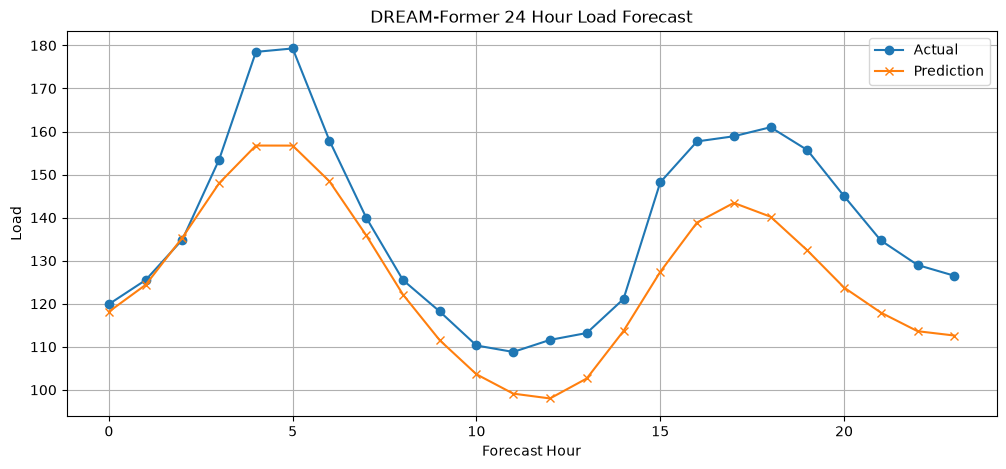

In [25]:
sample_id = 20


plt.figure(
    figsize=(12,5)
)


plt.plot(
    y_true[sample_id],
    marker="o",
    label="Actual"
)


plt.plot(
    pred[sample_id],
    marker="x",
    label="Prediction"
)


plt.xlabel(
    "Forecast Hour"
)


plt.ylabel(
    "Load"
)


plt.title(
    "DREAM-Former 24 Hour Load Forecast"
)


plt.legend()

plt.grid()

plt.show()

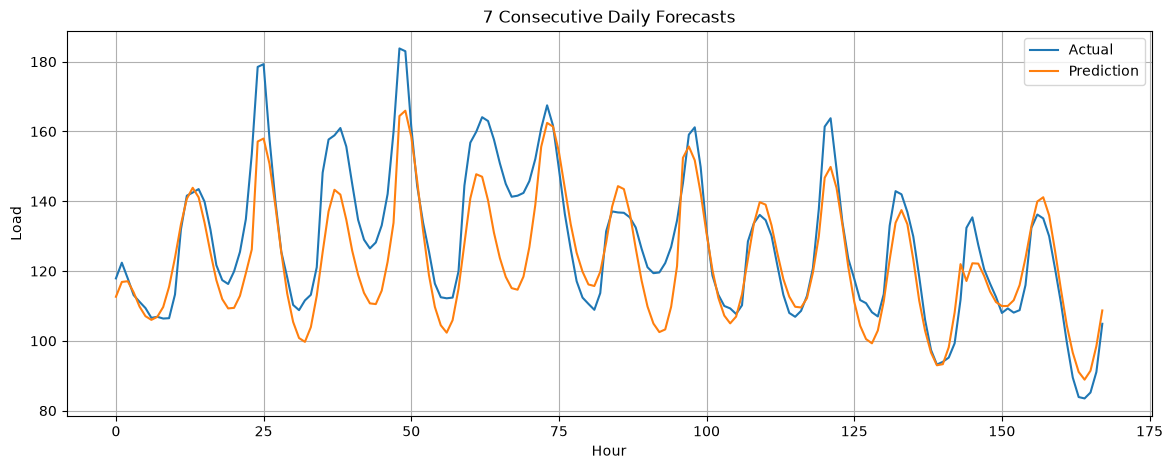

In [26]:
indices = [
    0,
    24,
    48,
    72,
    96,
    120,
    144
]


plt.figure(
    figsize=(14,5)
)


plt.plot(
    y_true[indices].flatten(),
    label="Actual"
)


plt.plot(
    pred[indices].flatten(),
    label="Prediction"
)


plt.xlabel(
    "Hour"
)


plt.ylabel(
    "Load"
)


plt.title(
    "7 Consecutive Daily Forecasts"
)


plt.legend()

plt.grid()

plt.show()